In [3]:
from google.colab import files
uploaded = files.upload()


Saving train_test_network.csv to train_test_network.csv


In [6]:
import pandas as pd

df = pd.read_csv("train_test_network.csv")

df.head()

,src_ip,src_port,dst_ip,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,...,http_response_body_len,http_status_code,http_user_agent,http_orig_mime_types,http_resp_mime_types,weird_name,weird_addl,weird_notice,label,type
0,192.168.1.37,4444,192.168.1.193,49178,tcp,-,290.371539,101568,2592,OTH,...,0,0,-,-,-,-,-,-,1,backdoor
1,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000102,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
2,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000148,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
3,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000113,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
4,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000130,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor


In [7]:
df['Bytes_Transferred'] = df['src_bytes'] + df['dst_bytes']
df['Source'] = df['src_ip']
df['Destination'] = df['dst_ip']
df['Protocol'] = df['proto']
df['Duration'] = df['duration']

In [8]:
df = df[['Source','Destination','Protocol','Duration','Bytes_Transferred']]

df = df.dropna()
df = df.drop_duplicates()

In [9]:
df['Connection_Frequency'] = df.groupby(['Source','Destination'])['Source'].transform('count')

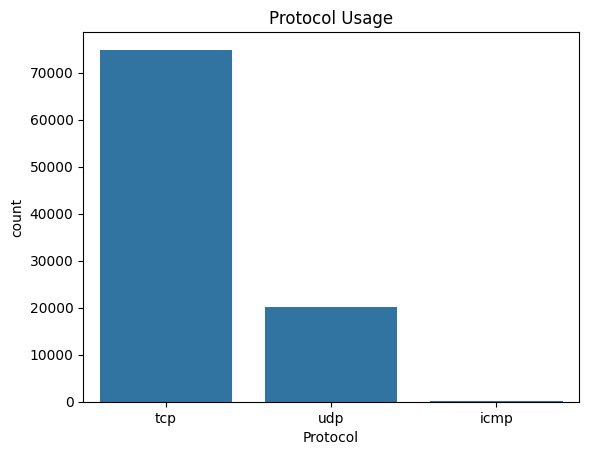

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x='Protocol', data=df)
plt.title("Protocol Usage")
plt.show()

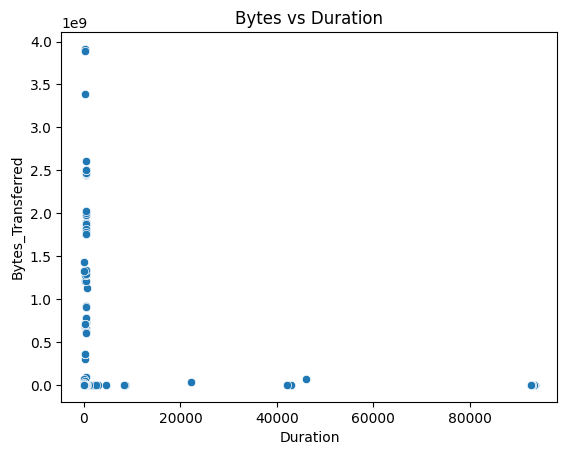

In [11]:
sns.scatterplot(x='Duration', y='Bytes_Transferred', data=df)
plt.title("Bytes vs Duration")
plt.show()

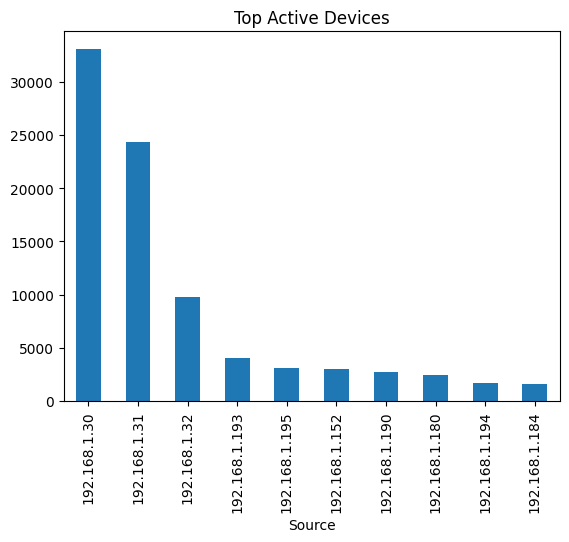

In [12]:
df['Source'].value_counts().head(10).plot(kind='bar')
plt.title("Top Active Devices")
plt.show()

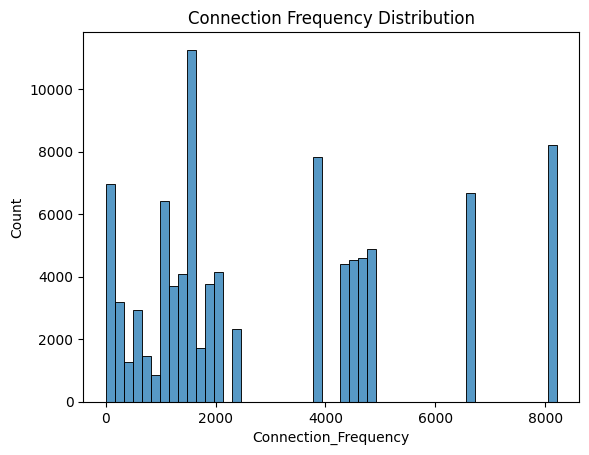

In [13]:
sns.histplot(df['Connection_Frequency'], bins=50)
plt.title("Connection Frequency Distribution")
plt.show()

In [14]:
df.describe()

,Duration,Bytes_Transferred,Connection_Frequency
count,95226.000000,9.522600e+04,95226.00000
mean,17.037053,1.144255e+06,3066.96041
std,839.745405,4.727643e+07,2448.70154
min,0.000000,0.000000e+00,1.00000
25%,0.003723,0.000000e+00,1226.00000
50%,0.131645,2.120000e+02,2024.00000
75%,1.018901,2.207000e+03,4604.00000
max,93516.929170,3.913853e+09,8209.00000


In [15]:
high_bytes = df[df['Bytes_Transferred'] > df['Bytes_Transferred'].quantile(0.95)]

In [16]:
high_freq = df[df['Connection_Frequency'] > df['Connection_Frequency'].quantile(0.95)]

In [17]:
long_conn = df[df['Duration'] > df['Duration'].quantile(0.95)]

In [18]:
features = df[['Bytes_Transferred','Duration','Connection_Frequency']]

In [19]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

In [20]:
from sklearn.neighbors import NearestNeighbors

knn = NearestNeighbors(n_neighbors=5)
knn.fit(X_scaled)

NearestNeighbors()

In [21]:
distances, _ = knn.kneighbors(X_scaled)

df['knn_score'] = distances.mean(axis=1)

In [22]:
threshold = df['knn_score'].quantile(0.95)

df['Anomaly'] = df['knn_score'] > threshold

In [30]:
df['Anomaly'].value_counts()

,count
Anomaly,
False,90464
True,4762


In [31]:
df['Protocol'].value_counts()

,count
Protocol,
tcp,74870
udp,20179
icmp,177


In [32]:
df.groupby('Source')['Bytes_Transferred'].sum().sort_values(ascending=False).head(5)

,Bytes_Transferred
Source,
192.168.1.31,67034579138
192.168.1.30,38655435193
192.168.1.32,2778496183
192.168.1.195,214184361
192.168.1.152,106447905


In [33]:
df['Bytes_Transferred'].describe()

,Bytes_Transferred
count,9.522600e+04
mean,1.144255e+06
std,4.727643e+07
min,0.000000e+00
25%,0.000000e+00
50%,2.120000e+02
75%,2.207000e+03
max,3.913853e+09


In [34]:
df['Connection_Frequency'].describe()

,Connection_Frequency
count,95226.00000
mean,3066.96041
std,2448.70154
min,1.00000
25%,1226.00000
50%,2024.00000
75%,4604.00000
max,8209.00000


In [35]:
df['Duration'].describe()

,Duration
count,95226.000000
mean,17.037053
std,839.745405
min,0.000000
25%,0.003723
50%,0.131645
75%,1.018901
max,93516.929170


In [36]:
df['Anomaly'].value_counts(normalize=True)

,proportion
Anomaly,
False,0.949993
True,0.050007
